Import Libraries

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Load Dataset

In [3]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/chennai_water_distribution_network.csv")

print("Shape:", df.shape)

Shape: (12000, 17)


In [4]:
df.head()

,Timestamp,City,Zone,Pipe_ID,Pipe_Length_km,Pipe_Diameter_mm,Pipe_Material,Pipe_Age_Years,Water_Supply_L_per_day,Water_Demand_L_per_day,Flow_Rate_L_per_s,Pressure_bar,Leakage_L_per_day,Temperature_C,Rainfall_mm,Maintenance_Events,Leakage_Incident
0,2025-01-01 00:00:00,Chennai,Central Zone,CHN-P-0378,3.73,200,DI,21,179916.86,128884.44,2.00,2.77,43912.974744,26.22,6.50,0,0
1,2025-01-01 01:00:00,Chennai,West Zone,CHN-P-0835,2.17,200,GI,40,85129.16,67374.60,1.12,3.47,55902.940609,25.78,3.29,2,0
2,2025-01-01 02:00:00,Chennai,South Zone,CHN-P-0817,3.23,200,PVC,4,188247.08,132325.85,2.33,3.36,26168.058152,32.54,1.77,1,0
3,2025-01-01 03:00:00,Chennai,South Zone,CHN-P-0746,3.41,150,GI,6,89801.48,74049.34,1.07,2.63,18041.444490,35.05,0.60,0,0
4,2025-01-01 04:00:00,Chennai,North Zone,CHN-P-0564,2.32,250,HDPE,2,167682.83,133596.73,1.74,3.48,13129.356660,33.66,0.53,0,0


Data Understanding

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Timestamp               12000 non-null  object 
 1   City                    12000 non-null  object 
 2   Zone                    12000 non-null  object 
 3   Pipe_ID                 12000 non-null  object 
 4   Pipe_Length_km          12000 non-null  float64
 5   Pipe_Diameter_mm        12000 non-null  int64  
 6   Pipe_Material           12000 non-null  object 
 7   Pipe_Age_Years          12000 non-null  int64  
 8   Water_Supply_L_per_day  12000 non-null  float64
 9   Water_Demand_L_per_day  12000 non-null  float64
 10  Flow_Rate_L_per_s       12000 non-null  float64
 11  Pressure_bar            12000 non-null  float64
 12  Leakage_L_per_day       12000 non-null  float64
 13  Temperature_C           12000 non-null  float64
 14  Rainfall_mm             12000 non-null

In [6]:
df.describe()

,Pipe_Length_km,Pipe_Diameter_mm,Pipe_Age_Years,Water_Supply_L_per_day,Water_Demand_L_per_day,Flow_Rate_L_per_s,Pressure_bar,Leakage_L_per_day,Temperature_C,Rainfall_mm,Maintenance_Events,Leakage_Incident
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
mean,2.762472,233.237500,20.906917,169955.451105,131821.410878,1.959437,3.108243,40399.764029,29.992392,2.496738,0.422333,0.100000
std,1.297489,98.486642,11.269605,51250.364485,41965.331609,0.598057,0.560040,14331.985733,3.455870,2.461199,0.758408,0.300013
min,0.500000,100.000000,2.000000,76063.930000,50187.590000,0.830000,1.200000,7896.673681,24.000000,0.000000,0.000000,0.000000
25%,1.650000,150.000000,11.000000,126218.262500,96960.457500,1.450000,2.730000,28727.039450,26.990000,0.710000,0.000000,0.000000
50%,2.770000,200.000000,21.000000,169254.135000,130442.205000,1.960000,3.100000,40295.861944,30.000000,1.740000,0.000000,0.000000
75%,3.890000,300.000000,31.000000,213598.462500,164253.700000,2.450000,3.490000,52225.622702,32.942500,3.480000,1.000000,0.000000
max,5.000000,400.000000,40.000000,274910.690000,244119.280000,3.300000,5.500000,77314.121353,36.000000,21.370000,4.000000,1.000000


Data Cleaning and Preparation


In [7]:
df.isnull().sum()

,0
Timestamp,0
City,0
Zone,0
Pipe_ID,0
Pipe_Length_km,0
Pipe_Diameter_mm,0
Pipe_Material,0
Pipe_Age_Years,0
Water_Supply_L_per_day,0
Water_Demand_L_per_day,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print(df["Timestamp"].dtype)

datetime64[ns]


In [10]:
print("Start Date:", df["Timestamp"].min())
print("End Date:", df["Timestamp"].max())

Start Date: 2025-01-01 00:00:00
End Date: 2026-05-15 23:00:00


Feature Engineering

In [11]:
df["Water_Loss_L_per_day"] = (df["Water_Supply_L_per_day"] - df["Water_Demand_L_per_day"])

df["Loss_Percentage"] = (df["Water_Loss_L_per_day"] / df["Water_Supply_L_per_day"]) * 100

print(df[["Water_Supply_L_per_day","Water_Demand_L_per_day","Water_Loss_L_per_day","Loss_Percentage"]].head())

   Water_Supply_L_per_day  Water_Demand_L_per_day  Water_Loss_L_per_day  \
0               179916.86               128884.44              51032.42   
1                85129.16                67374.60              17754.56   
2               188247.08               132325.85              55921.23   
3                89801.48                74049.34              15752.14   
4               167682.83               133596.73              34086.10   

   Loss_Percentage  
0        28.364446  
1        20.856026  
2        29.706293  
3        17.541069  
4        20.327722  


Exploratory Data Analysis

In [12]:
zone_loss = df.groupby("Zone")["Water_Loss_L_per_day"].mean()

zone_loss = zone_loss.sort_values(ascending=False)

print(zone_loss)

Zone
Central Zone    40659.408501
North Zone      38849.650566
West Zone       37511.502496
South Zone      35455.595423
Name: Water_Loss_L_per_day, dtype: float64


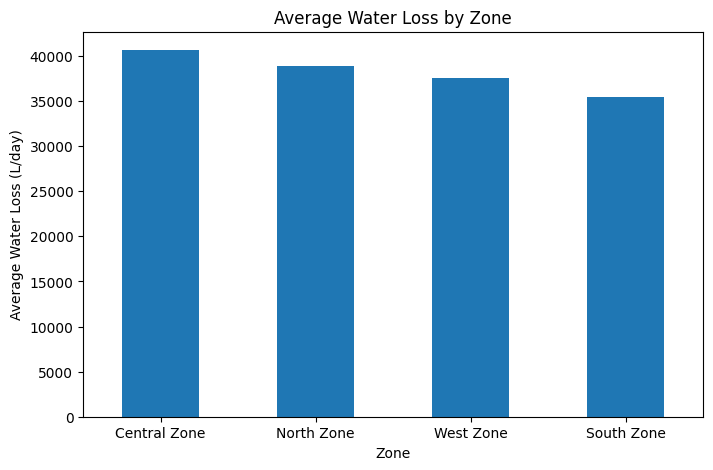

In [13]:
zone_loss.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Zone")
plt.ylabel("Average Water Loss (L/day)")
plt.title("Average Water Loss by Zone")
plt.xticks(rotation=0)
plt.show()

In [14]:
zone_summary = df.groupby("Zone")[["Water_Supply_L_per_day","Water_Demand_L_per_day","Water_Loss_L_per_day"]].mean()

zone_summary = zone_summary.sort_values("Water_Loss_L_per_day",ascending=False)

print(zone_summary)

              Water_Supply_L_per_day  Water_Demand_L_per_day  \
Zone                                                           
Central Zone           182794.349957           142134.941456   
North Zone             173827.445278           134977.794712   
West Zone              166064.286395           128552.783900   
South Zone             156818.001315           121362.405892   

              Water_Loss_L_per_day  
Zone                                
Central Zone          40659.408501  
North Zone            38849.650566  
West Zone             37511.502496  
South Zone            35455.595423  


In [15]:
zone_loss_percentage = df.groupby("Zone")["Loss_Percentage"].mean()

zone_loss_percentage = zone_loss_percentage.sort_values(ascending=False)

print(zone_loss_percentage)

Zone
South Zone      22.604952
West Zone       22.599945
North Zone      22.370060
Central Zone    22.284507
Name: Loss_Percentage, dtype: float64


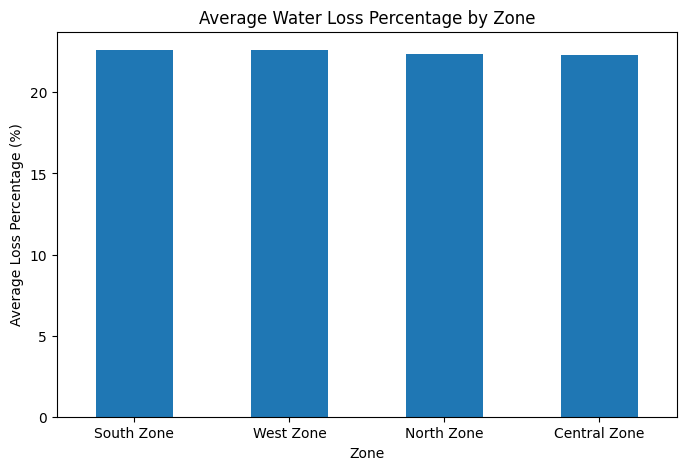

In [16]:
zone_loss_percentage.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Zone")
plt.ylabel("Average Loss Percentage (%)")
plt.title("Average Water Loss Percentage by Zone")
plt.xticks(rotation=0)
plt.show()

In [17]:
zone_leakage = df.groupby("Zone")["Leakage_L_per_day"].mean()

zone_leakage = zone_leakage.sort_values(ascending=False)

print(zone_leakage)

Zone
Central Zone    41048.244830
West Zone       40550.027651
North Zone      40393.091870
South Zone      39599.483260
Name: Leakage_L_per_day, dtype: float64


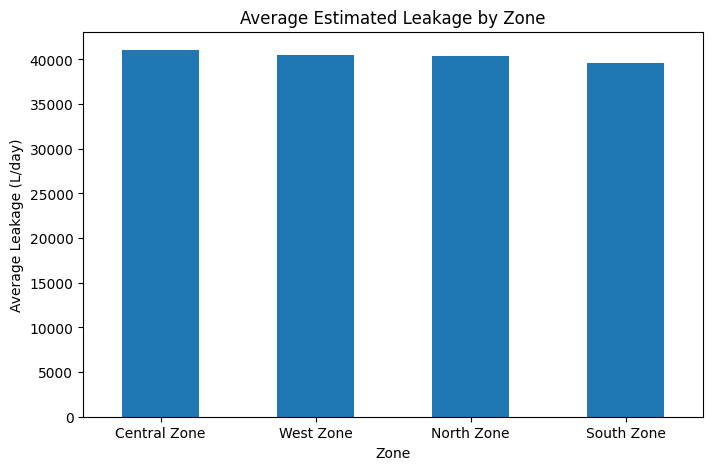

In [18]:
zone_leakage.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Zone")
plt.ylabel("Average Leakage (L/day)")
plt.title("Average Estimated Leakage by Zone")
plt.xticks(rotation=0)
plt.show()

In [19]:
age_leakage = df.groupby("Pipe_Age_Years")["Leakage_L_per_day"].mean()
print(age_leakage)

Pipe_Age_Years
2     17505.475745
3     18562.567781
4     20124.678531
5     21649.770647
6     22062.528716
7     23598.694936
8     24981.826753
9     25981.125553
10    27178.256515
11    28475.629055
12    30169.619615
13    30945.594931
14    32505.277438
15    33492.796924
16    34701.534753
17    35735.287923
18    36549.407477
19    37633.006463
20    39256.362049
21    40286.385154
22    41519.425308
23    43132.391962
24    44020.145745
25    45585.650846
26    46722.435586
27    48038.567356
28    48594.492881
29    50077.712269
30    51687.078974
31    52858.450469
32    53402.191835
33    54809.325927
34    56018.616592
35    57239.455937
36    59078.117525
37    59622.656032
38    60704.336666
39    62180.956858
40    63376.968947
Name: Leakage_L_per_day, dtype: float64


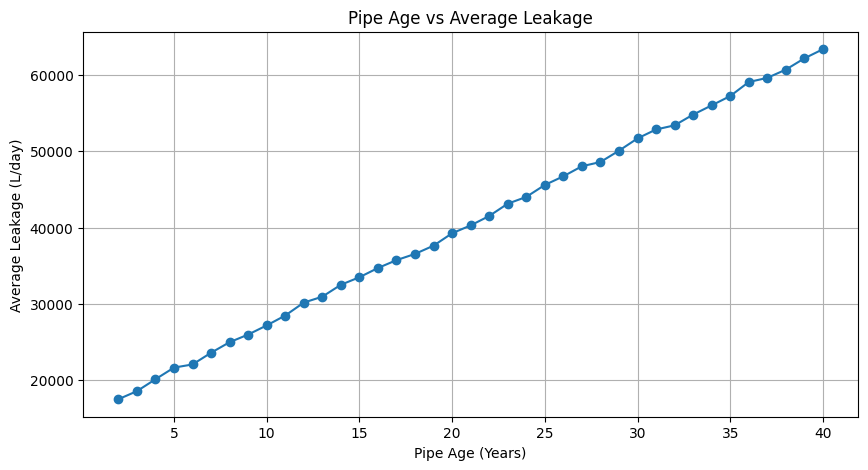

In [20]:
age_leakage.plot(kind="line", marker="o", figsize=(10, 5))
plt.xlabel("Pipe Age (Years)")
plt.ylabel("Average Leakage (L/day)")
plt.title("Pipe Age vs Average Leakage")
plt.grid(True)
plt.show()

In [21]:
pressure_leakage = df.groupby("Pressure_bar")["Leakage_L_per_day"].mean()
print(pressure_leakage)

Pressure_bar
1.20    40711.495905
1.22    20064.198826
1.24    10585.799473
1.25    30099.247837
1.26    37266.045672
            ...     
5.10    43856.830487
5.12    39047.112615
5.26    50918.793589
5.40    41955.753273
5.50    45853.877707
Name: Leakage_L_per_day, Length: 354, dtype: float64


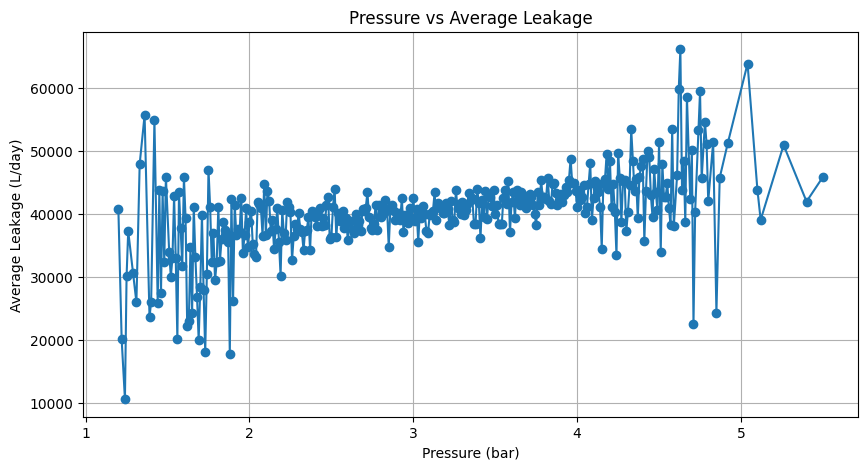

In [22]:
pressure_leakage.plot(kind="line", marker="o", figsize=(10, 5))
plt.xlabel("Pressure (bar)")
plt.ylabel("Average Leakage (L/day)")
plt.title("Pressure vs Average Leakage")
plt.grid(True)
plt.show()

In [23]:
flow_leakage = df.groupby("Flow_Rate_L_per_s")["Leakage_L_per_day"].mean()
print(flow_leakage)

Flow_Rate_L_per_s
0.83    45381.589986
0.84    26380.782781
0.85    41549.188480
0.86    34500.750724
0.87    33548.042351
            ...     
3.26    51367.784772
3.27    43627.194531
3.28    30736.029658
3.29    45713.489555
3.30    54014.266458
Name: Leakage_L_per_day, Length: 248, dtype: float64


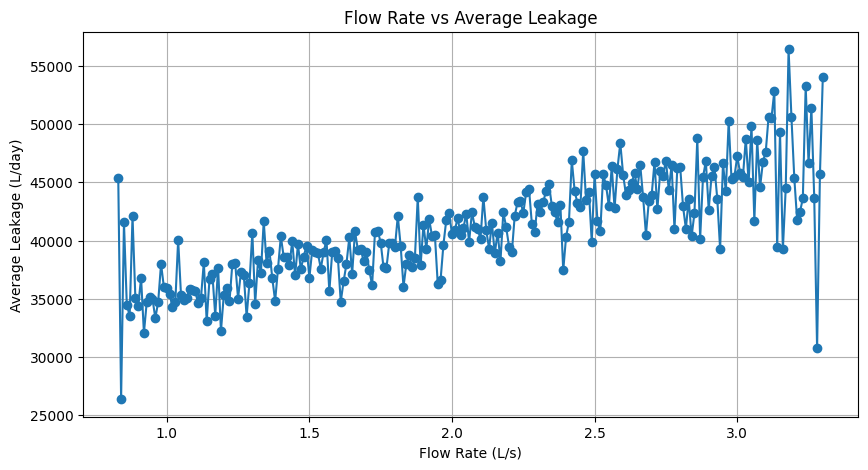

In [24]:
flow_leakage.plot(kind="line", marker="o", figsize=(10, 5))
plt.xlabel("Flow Rate (L/s)")
plt.ylabel("Average Leakage (L/day)")
plt.title("Flow Rate vs Average Leakage")
plt.grid(True)
plt.show()

In [25]:
material_leakage = df.groupby("Pipe_Material")["Leakage_L_per_day"].mean()

material_leakage = material_leakage.sort_values(ascending=False)

print(material_leakage)

Pipe_Material
PVC     40455.513673
HDPE    40409.795495
DI      40403.523791
GI      40329.246585
Name: Leakage_L_per_day, dtype: float64


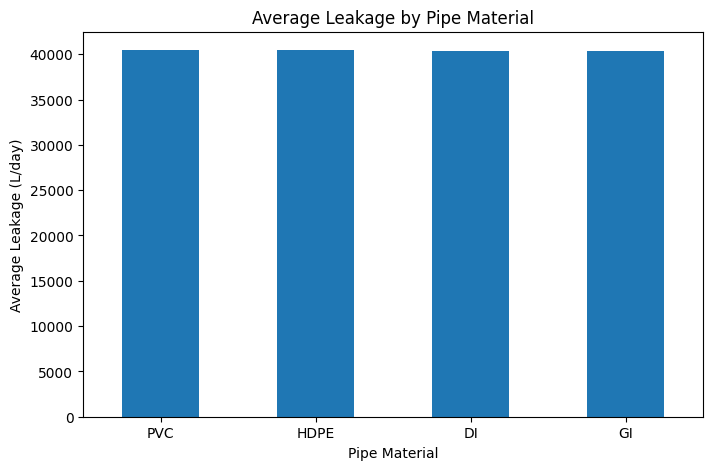

In [26]:
material_leakage.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Pipe Material")
plt.ylabel("Average Leakage (L/day)")
plt.title("Average Leakage by Pipe Material")
plt.xticks(rotation=0)
plt.show()

In [27]:
numeric_columns = ["Pipe_Length_km","Pipe_Diameter_mm","Pipe_Age_Years","Water_Supply_L_per_day","Water_Demand_L_per_day","Flow_Rate_L_per_s",
                   "Pressure_bar","Leakage_L_per_day","Temperature_C","Rainfall_mm","Maintenance_Events"]

correlation = df[numeric_columns].corr()

leakage_correlation = correlation["Leakage_L_per_day"]

leakage_correlation = leakage_correlation.sort_values(ascending=False)

print(leakage_correlation)

Leakage_L_per_day         1.000000
Pipe_Age_Years            0.945872
Water_Supply_L_per_day    0.228171
Flow_Rate_L_per_s         0.224964
Water_Demand_L_per_day    0.161119
Pressure_bar              0.115319
Pipe_Length_km            0.052414
Pipe_Diameter_mm          0.012996
Temperature_C             0.009667
Maintenance_Events        0.005561
Rainfall_mm               0.003866
Name: Leakage_L_per_day, dtype: float64


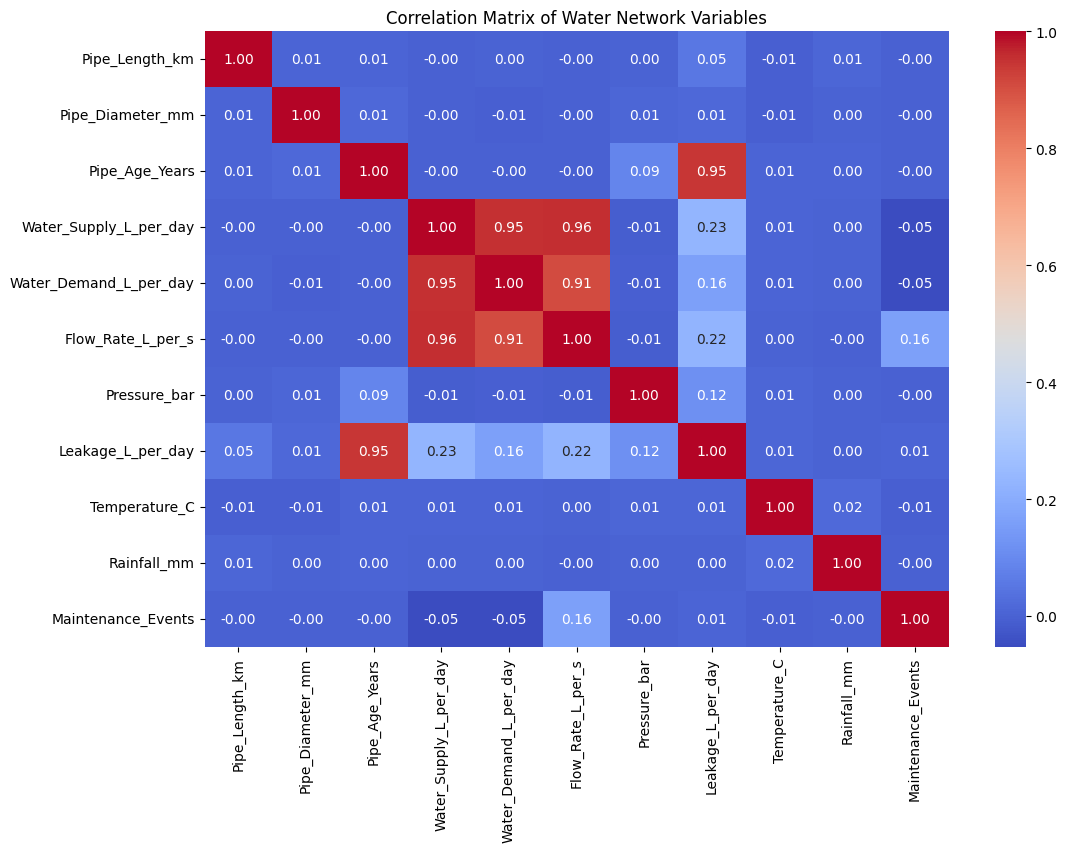

In [28]:
plt.figure(figsize=(12, 8))
sns.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Matrix of Water Network Variables")
plt.show()

ML Preparation

In [29]:
features = ["Pipe_Length_km","Pipe_Diameter_mm","Pipe_Age_Years","Water_Supply_L_per_day","Water_Demand_L_per_day","Flow_Rate_L_per_s",
    "Pressure_bar","Temperature_C","Rainfall_mm","Maintenance_Events"]

X = df[features]
y = df["Leakage_L_per_day"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (12000, 10)
Target shape: (12000,)


In [30]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (9600, 10)
Testing data: (2400, 10)


Model Evaluation

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R²  :", r2_linear)

Linear Regression Results
MAE : 1440.8258134918756
RMSE: 1819.62781574411
R²  : 0.9839484104589741


In [32]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100,random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Results
MAE : 1750.8267516188444
RMSE: 2198.5782408792124
R²  : 0.9765665213960644


In [33]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(n_estimators=100,learning_rate=0.05,max_depth=3,random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Gradient Boosting Results")
print("MAE :", mae_gb)
print("RMSE:", rmse_gb)
print("R²  :", r2_gb)

Gradient Boosting Results
MAE : 2297.163033458051
RMSE: 2846.717675788322
R²  : 0.9607136476323366


Model Comparison

In [34]:
model_results = pd.DataFrame({
    "Model": ["Linear Regression","Random Forest","Gradient Boosting"],
    "MAE": [mae_linear,mae_rf,mae_gb],
    "RMSE": [rmse_linear,rmse_rf,rmse_gb],
    "R2": [r2_linear,r2_rf,r2_gb]})

print(model_results)

               Model          MAE         RMSE        R2
0  Linear Regression  1440.825813  1819.627816  0.983948
1      Random Forest  1750.826752  2198.578241  0.976567
2  Gradient Boosting  2297.163033  2846.717676  0.960714


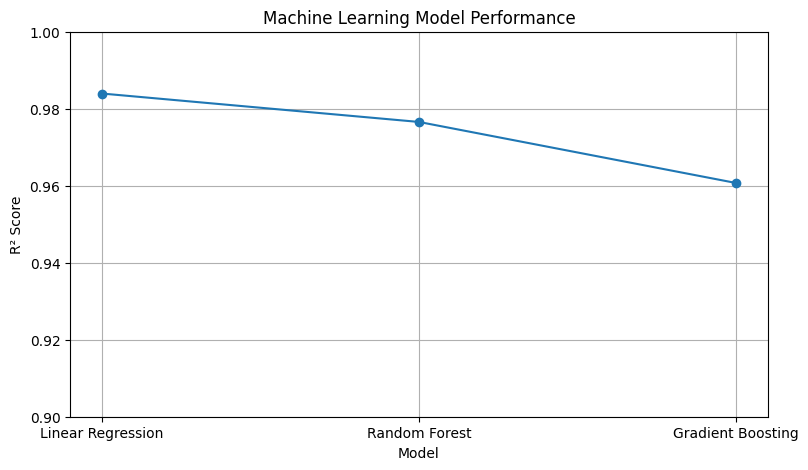

In [35]:
plt.figure(figsize=(9, 5))
plt.plot(model_results["Model"],model_results["R2"],marker="o")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Machine Learning Model Performance")
plt.ylim(0.9, 1.0)
plt.grid(True)
plt.show()

Final Model Analysis

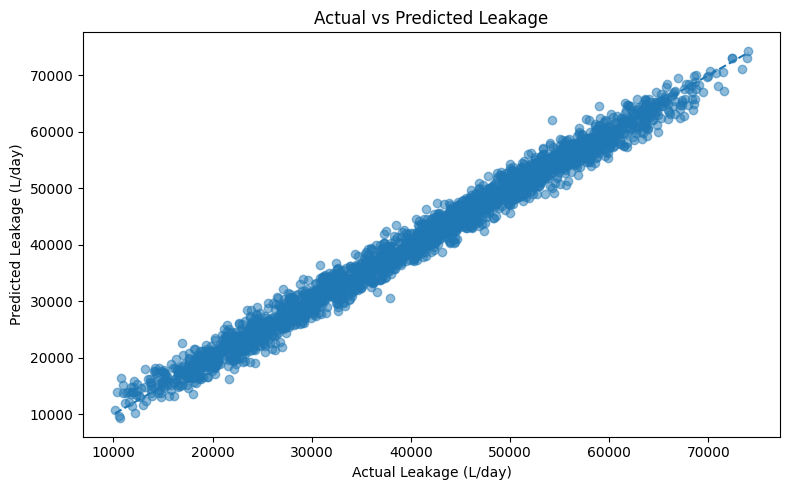

In [36]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test,y_pred_linear,alpha=0.5)
plt.xlabel("Actual Leakage (L/day)")
plt.ylabel("Predicted Leakage (L/day)")
plt.title("Actual vs Predicted Leakage")
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],linestyle="--")
plt.tight_layout()
plt.show()

In [37]:
feature_coefficients = pd.DataFrame({"Feature": features,"Coefficient": linear_model.coef_})
feature_coefficients = feature_coefficients.sort_values("Coefficient",ascending=False)
print(feature_coefficients)

                  Feature  Coefficient
5       Flow_Rate_L_per_s  1661.223578
2          Pipe_Age_Years  1198.693730
6            Pressure_bar   853.172594
0          Pipe_Length_km   515.143872
9      Maintenance_Events    21.463601
7           Temperature_C     5.865937
3  Water_Supply_L_per_day     0.202380
1        Pipe_Diameter_mm     0.043395
4  Water_Demand_L_per_day    -0.200771
8             Rainfall_mm    -1.218036


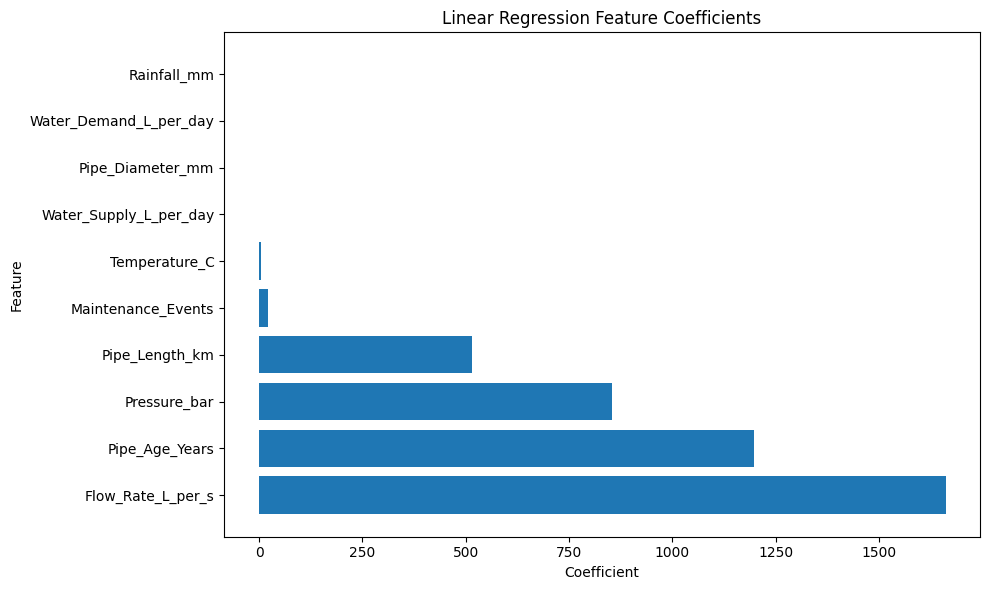

In [38]:
plt.figure(figsize=(10, 6))
plt.barh(feature_coefficients["Feature"],feature_coefficients["Coefficient"])
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Linear Regression Feature Coefficients")
plt.tight_layout()
plt.show()

Save Final Model

In [39]:
import joblib

joblib.dump(linear_model, "water_leakage_model.pkl")
print("Model saved successfully.")

Model saved successfully.


In [40]:
import os

print("Model file exists:", os.path.exists("water_leakage_model.pkl"))

Model file exists: True


Streamlit installation and App Running


In [41]:
!pip install streamlit -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 43.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 71.4 MB/s eta 0:00:00


In [42]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib


# --------------------------------------------------
# Load trained model
# --------------------------------------------------

model = joblib.load("water_leakage_model.pkl")


# --------------------------------------------------
# Page settings
# --------------------------------------------------

st.set_page_config(
    page_title="Water Distribution Network Loss Analytics",
    page_icon="💧",
    layout="wide"
)


# --------------------------------------------------
# Custom styling
# --------------------------------------------------

st.markdown("""
<style>

.main-title {
    font-size: 38px;
    font-weight: 700;
    margin-bottom: 5px;
}

.subtitle {
    font-size: 17px;
    color: #666666;
    margin-bottom: 25px;
}

.section-title {
    font-size: 24px;
    font-weight: 600;
    margin-top: 20px;
    margin-bottom: 15px;
}

.precaution-box {
    padding: 15px;
    border-radius: 10px;
    background-color: #f1f8ff;
    color: #222222;
    border-left: 5px solid #2196f3;
    margin-bottom: 10px;
}

.info-box {
    padding: 12px;
    border-radius: 8px;
    background-color: #f8f9fa;
    color: #333333;
    border: 1px solid #dddddd;
    margin-bottom: 15px;
}

</style>
""", unsafe_allow_html=True)


# --------------------------------------------------
# Header
# --------------------------------------------------

st.markdown(
    '<div class="main-title">'
    '💧 Water Distribution Network Loss Analytics'
    '</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">'
    'Analyze network conditions and predict potential water leakage '
    'using machine learning.'
    '</div>',
    unsafe_allow_html=True
)

st.divider()


# --------------------------------------------------
# Location Information
# --------------------------------------------------

st.markdown(
    '<div class="section-title">📍 Network Information</div>',
    unsafe_allow_html=True
)

location_col1, location_col2 = st.columns(2)

with location_col1:

    city = st.selectbox(
        "City",
        ["Chennai"]
    )

with location_col2:

    zone = st.selectbox(
        "Zone",
        [
            "North Zone",
            "Central Zone",
            "South Zone",
            "West Zone"
        ]
    )


# --------------------------------------------------
# Network Parameters
# --------------------------------------------------

st.markdown(
    '<div class="section-title">⚙️ Network Parameters</div>',
    unsafe_allow_html=True
)

col1, col2, col3 = st.columns(3)


# --------------------------------------------------
# Column 1
# --------------------------------------------------

with col1:

    pipe_length = st.number_input(
        "Pipe Length (km)",
        min_value=0.5,
        max_value=5.0,
        value=2.5,
        step=0.1
    )

    pipe_diameter = st.number_input(
        "Pipe Diameter (mm)",
        min_value=100,
        max_value=400,
        value=250,
        step=10
    )

    pipe_age = st.number_input(
        "Pipe Age (years)",
        min_value=2,
        max_value=40,
        value=20,
        step=1
    )


# --------------------------------------------------
# Column 2
# --------------------------------------------------

with col2:

    water_supply = st.number_input(
        "Water Supply (L/day)",
        min_value=50000.0,
        max_value=300000.0,
        value=170000.0,
        step=1000.0
    )

    water_demand = st.number_input(
        "Water Demand (L/day)",
        min_value=50000.0,
        max_value=300000.0,
        value=130000.0,
        step=1000.0
    )

    flow_rate = st.number_input(
        "Flow Rate (L/s)",
        min_value=0.8,
        max_value=3.5,
        value=2.0,
        step=0.1
    )


# --------------------------------------------------
# Column 3
# --------------------------------------------------

with col3:

    pressure = st.number_input(
        "Pressure (bar)",
        min_value=1.0,
        max_value=6.0,
        value=3.0,
        step=0.1
    )

    temperature = st.number_input(
        "Temperature (°C)",
        min_value=20.0,
        max_value=40.0,
        value=30.0,
        step=1.0
    )

    rainfall = st.number_input(
        "Rainfall (mm)",
        min_value=0.0,
        max_value=25.0,
        value=2.0,
        step=0.1
    )


# --------------------------------------------------
# Maintenance
# --------------------------------------------------

maintenance = st.number_input(
    "Maintenance Events",
    min_value=0,
    max_value=4,
    value=1,
    step=1
)


st.divider()


# --------------------------------------------------
# Prediction Button
# --------------------------------------------------

predict_button = st.button(
    "🔮 Predict Leakage",
    use_container_width=True
)


# --------------------------------------------------
# Prediction
# --------------------------------------------------

if predict_button:

    # --------------------------------------------------
    # Validate supply and demand
    # --------------------------------------------------

    if water_demand > water_supply:

        st.error(
            "Water demand should not be greater than water supply. "
            "Please enter valid network values."
        )

        st.stop()


    # --------------------------------------------------
    # Calculate water loss
    # --------------------------------------------------

    water_loss = water_supply - water_demand

    if water_supply > 0:

        loss_percentage = (
            water_loss / water_supply
        ) * 100

    else:

        loss_percentage = 0


    # --------------------------------------------------
    # Prepare model input
    # --------------------------------------------------

    user_data = pd.DataFrame({

        "Pipe_Length_km": [pipe_length],

        "Pipe_Diameter_mm": [pipe_diameter],

        "Pipe_Age_Years": [pipe_age],

        "Water_Supply_L_per_day": [water_supply],

        "Water_Demand_L_per_day": [water_demand],

        "Flow_Rate_L_per_s": [flow_rate],

        "Pressure_bar": [pressure],

        "Temperature_C": [temperature],

        "Rainfall_mm": [rainfall],

        "Maintenance_Events": [maintenance]

    })


    # --------------------------------------------------
    # Model Prediction
    # --------------------------------------------------

    predicted_leakage = model.predict(user_data)[0]


    # --------------------------------------------------
    # Risk Classification
    # --------------------------------------------------

    if predicted_leakage < 30000:

        risk_level = "Low"

    elif predicted_leakage < 50000:

        risk_level = "Medium"

    else:

        risk_level = "High"


    # --------------------------------------------------
    # Prediction Results
    # --------------------------------------------------

    st.markdown(
        '<div class="section-title">'
        '📊 Prediction Results'
        '</div>',
        unsafe_allow_html=True
    )

    result_col1, result_col2, result_col3, result_col4 = st.columns(4)


    with result_col1:

        st.metric(
            "Predicted Leakage",
            f"{predicted_leakage:,.2f} L/day"
        )


    with result_col2:

        st.metric(
            "Risk Level",
            risk_level
        )


    with result_col3:

        st.metric(
            "Water Loss",
            f"{water_loss:,.2f} L/day"
        )


    with result_col4:

        st.metric(
            "Loss Percentage",
            f"{loss_percentage:.2f}%"
        )


    st.divider()


    # --------------------------------------------------
    # Recommended Actions
    # --------------------------------------------------

    st.markdown(
        '<div class="section-title">'
        '🛠️ Recommended Actions'
        '</div>',
        unsafe_allow_html=True
    )


    precautions = []


    # --------------------------------------------------
    # Risk-based recommendations
    # --------------------------------------------------

    if risk_level == "Low":

        precautions.append(
            "Continue routine leakage monitoring for the selected zone."
        )

        precautions.append(
            "Maintain scheduled preventive maintenance for the network."
        )

        precautions.append(
            "Periodically compare water supply and demand to identify changes "
            "in water loss."
        )


    elif risk_level == "Medium":

        precautions.append(
            "Increase monitoring frequency for the selected network section."
        )

        precautions.append(
            "Carry out a targeted inspection of the network section."
        )

        precautions.append(
            "Check pressure and flow measurements for unusual changes."
        )

        precautions.append(
            "Review recent maintenance history and schedule preventive "
            "maintenance where required."
        )


    else:

        precautions.append(
            "Prioritize the selected zone for detailed leakage investigation."
        )

        precautions.append(
            "Conduct field inspection and targeted leak-detection checks."
        )

        precautions.append(
            "Assess pressure and flow conditions before deciding on "
            "corrective action."
        )

        precautions.append(
            "Repair confirmed leaks promptly after field verification."
        )

        precautions.append(
            "Evaluate older or problematic pipe sections for rehabilitation "
            "or replacement."
        )


    # --------------------------------------------------
    # Pipe age recommendation
    # --------------------------------------------------

    if pipe_age >= 30:

        precautions.append(
            "The pipe section is relatively old. Evaluate its condition "
            "for rehabilitation or replacement."
        )


    # --------------------------------------------------
    # Pressure recommendation
    # --------------------------------------------------

    if pressure >= 5:

        precautions.append(
            "Review the pressure condition and verify whether it is within "
            "the required operating range for the network."
        )


    # --------------------------------------------------
    # Flow recommendation
    # --------------------------------------------------

    if flow_rate >= 2.5:

        precautions.append(
            "Monitor flow measurements and investigate unusual flow "
            "patterns in the selected section."
        )


    # --------------------------------------------------
    # Maintenance recommendation
    # --------------------------------------------------

    if maintenance == 0:

        precautions.append(
            "No recent maintenance events were entered. Schedule preventive "
            "inspection and maintenance for the network section."
        )


    # --------------------------------------------------
    # Water loss recommendation
    # --------------------------------------------------

    if loss_percentage >= 25:

        precautions.append(
            "The supply-demand difference is relatively high. Carry out a "
            "water-balance review and investigate possible sources of loss."
        )


    # --------------------------------------------------
    # Display recommendations
    # --------------------------------------------------

    for precaution in precautions:

        st.markdown(
            f'<div class="precaution-box">'
            f'🔹 {precaution}'
            f'</div>',
            unsafe_allow_html=True
        )


    # --------------------------------------------------
    # Network Summary
    # --------------------------------------------------

    st.markdown(
        '<div class="section-title">'
        '📋 Network Summary'
        '</div>',
        unsafe_allow_html=True
    )


    summary = pd.DataFrame({

        "Parameter": [

            "City",

            "Zone",

            "Pipe Age",

            "Pipe Length",

            "Pipe Diameter",

            "Water Supply",

            "Water Demand",

            "Flow Rate",

            "Pressure",

            "Temperature",

            "Rainfall",

            "Maintenance Events"

        ],

        "Value": [

            city,

            zone,

            f"{pipe_age} years",

            f"{pipe_length} km",

            f"{pipe_diameter} mm",

            f"{water_supply:,.0f} L/day",

            f"{water_demand:,.0f} L/day",

            f"{flow_rate} L/s",

            f"{pressure} bar",

            f"{temperature} °C",

            f"{rainfall} mm",

            maintenance

        ]

    })


    st.dataframe(
        summary,
        use_container_width=True,
        hide_index=True
    )


    # --------------------------------------------------
    # Project Note
    # --------------------------------------------------

    st.markdown(
        '<div class="info-box">'
        'ℹ️ The predicted leakage and risk level are model-based estimates. '
        'Recommended actions are decision-support suggestions based on the '
        'entered network conditions and should be verified through field '
        'inspection and network measurements.'
        '</div>',
        unsafe_allow_html=True
    )


# --------------------------------------------------
# Footer
# --------------------------------------------------

st.divider()

st.caption(
    "Water Distribution Network Loss Analytics | "
    "Machine Learning based leakage prediction"
)

Writing app.py


In [43]:
!ls

app.py	drive  sample_data  water_leakage_model.pkl


In [44]:
import joblib

joblib.dump(linear_model, "water_leakage_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [45]:
!ls

app.py	drive  sample_data  water_leakage_model.pkl


In [46]:
!streamlit run app.py > streamlit.log 2>&1 &

In [47]:
!cat streamlit.log

In [48]:
!pip install pyngrok -q

In [49]:
!ngrok config add-authtoken 3JxFne1IITxjkSIc6K0ydRLSOtS_2754S7yQoafkJgq8nR9c7

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [50]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)

print("Streamlit App URL:")
print(public_url)

Streamlit App URL:
NgrokTunnel: "https://apprehend-throng-pavilion.ngrok-free.dev" -> "http://localhost:8501"
